In [251]:
#Packages
import seaborn as sns
import pandas as pd
import scipy
import IPython
import sklearn
import matplotlib.pyplot as plt
import numpy as np
import os
import requests
import plotly.express as px
import plotly.graph_objects as go

# Loading the datasets

[Healthcare dataset kaggle: https://www.kaggle.com/datasets/nudratabbas/healthcare-fraud-detection-dataset?utm_source=copilot.com]

Private premiums:

Premiums were analyzed using the second-lowest cost silver (benchmark) premium for a 40-year-old in each county and weighted by county plan selections, and may include premiums for non-Essential Health Benefits. In some state-based marketplaces, the premium data for some years are at the rating area level or zip level and are mapped to counties before weighting by county plan selections.	

Sources	
KFF analysis of data from Healthcare.gov, state rate review websites, state plan finder tools, and state provided data.	

[https://www.kff.org/state-indicator/?s=Marketplace+Average+Monthly+Benchmark+Premiums]

Medicare premiums:

The ‘persons with utilization' counts do not reflect beneficiaries who received covered services, but for whom no program payments were reported. Counts and amounts may not sum to totals because of rounding.  The counts also do not sum to totals because beneficiaries may have used both Part A and Part B services during the reported year.												

Sources								
Centers for Medicare & Medicaid Services, Office of Enterprise Data and Analytics, Chronic Conditions Data Warehouse.	

[https://www.kff.org/medicare/state-indicator/per-beneficiary/?currentTimeframe=0&sortModel=%7B%22colId%22:%22Location%22,%22sort%22:%22asc%22%7D]

1. Total Traditional Medicare Part A and/or Part B Enrollees : A count of unique human beings living in the state who are enrolled in Traditional Medicare (Part A, Part B, or both)

2. Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee: A calculated rate representing the average dollars spent by Medicare per beneficiary in that state

Medicaid Premiums:

Estimates here may not match other sources due to enrollment categorization differences and differences in measures of Medicaid spending. The spending data used in these estimates are from Medicaid claims which reflect spending at the time health care services are used or premium payments are made, whereas other measures of spending may reflect the timing of state payments to providers. Additionally, estimates here do not include prescription drug rebates and most supplemental payments to providers, which other Medicaid spending sources may include. 


A small number of Medicaid enrollees whose eligibility group is unknown are not broken out into a separate column but are included in state and national totals.

States with "Unusable" data quality according to the CMS DQ Atlas indicators "Medicaid-Only Enrollment", "Eligibility Group Code", "Age", "Restricted Benefits Code" and "Medicaid Beneficiary Expenditures" are not included in these tables and are not included in national totals. For more information on data quality issues that may lead to unusual spending or enrollment, see CMS DQ Atlas. Caution is recommended when comparing data between years since different states may be included in each year due to data quality.					

Sources					
KFF analysis of the T-MSIS Research Identifiable Files, 2023 (Preliminary)					

[https://www.kff.org/medicaid/state-indicator/medicaid-spending-per-full-benefit-enrollee/?currentTimeframe=0&sortModel=%7B%22colId%22:%22Location%22,%22sort%22:%22asc%22%7D]

Definitions							
*N/A:* Not Applicable. These states had not adopted the ACA Medicaid expansion as of the reporting year.							
                            
*NSD:* Not Significant Data. Due to data security measures, the values of cells with fewer than 50 enrollees are not reported but are included in state and national totals.							
                            
*DQ:* Data Quality. Data categorized as "Unusable" based on the DQ Atlas. These values are not included in the national totals, unless otherwise specified in a footnote.							
                            
*Full-Benefit Medicaid Enrollees:* Full-benefit enrollees are those who are enrolled in Medicaid for at least 1 month with full benefits or those who received at least one month of benefits through an alternative package of benchmark equivalent coverage. They may have not actually used any services during this period, but they are reported as enrolled in the program and are eligible to receive services.							
                            
*Seniors:* Enrollees age 65 and older.							
                            
*People with Disabilities:* Enrollees under age 65 who are reported as eligible due to a disability.							
                            
*Adults:* Enrollees ages 19 to 64 who are not eligible due to a disability or newly eligible for Medicaid by the ACA Medicaid expansion.							
                            
*Children:* Enrollees ages 18 and younger who are not eligible due to a disability.							
                            
*ACA Expansion Adults:* Enrollees ages 19 to 64 who were made newly eligible for Medicaid by the ACA Medicaid expansion.							
                            
                            
Footnotes							
1. Denotes "High Concern" data quality according to the CMS DQ Atlas for at least one of the following indicators: "Medicaid-Only Enrollment", "Eligibility Group Code", "Age", "Medicaid Beneficiary Expenditures," "Restricted Benefits Code." This applies across all columns.							
2. Denotes "High Concern" data quality according to the CMS DQ Atlas for the "Adult Expansion Enrollment" indicator. This only applies to the ACA Expansion Adults eligibility column.							
3. A significant majority of Florida’s child Medicaid enrollees have an eligibility code suggesting they came in through a medically-needy pathway. Those children age categorized as "disabled" based on their eligibility group even though they are under the age of 19.							
4. State reports a small number of adults as ACA expansion adults even though they have not expanded Medicaid coverage. KFF manually recodes these enrollees as Adult enrollees.							

In [252]:
print("-----RAW DATA------\n")
print("-----Healthcare dataset------\n")
health_data = pd.read_csv("healthcare_fraud_detection.csv")
print(health_data.shape)
print(health_data.head(3))

print("-----Private Premiums dataset------\n")
private_data = pd.read_csv("private_premiums.csv")
print(private_data.shape)
print(private_data.head(3))


print("-----Medicare Premiums dataset------\n")
medicare_data = pd.read_csv("medicare_premiums.csv")
medicare_data = medicare_data[['State', 'Total Traditional Medicare Part A and/or Part B Enrollees', 
                               'Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee']]
print(medicare_data.shape)
print(medicare_data.head(3))


print("-----Medicaid Premiums dataset------\n")
medicaid_data = pd.read_csv("medicaid-premiums.csv")
print(medicaid_data.shape)
print(medicaid_data.head(3))

-----RAW DATA------

-----Healthcare dataset------

(10000, 20)
  Provider_ID  Claim_ID  Patient_Age Patient_Gender Diagnosis_Code  \
0       P0052  C0000000           37           Male         I25.10   
1       P0121  C0000001           21         Female          E11.9   
2       P0140  C0000002           78         Female          J06.9   

   Procedure_Code  Claim_Amount  Approved_Amount Insurance_Type  \
0           36415        443.51           393.16       Medicaid   
1           99213        467.50           461.33       Self-Pay   
2           93000        591.69           530.06       Medicaid   

  Claim_Submission_Date  Days_Between_Service_and_Claim  \
0                9/1/24                              13   
1                9/5/22                               5   
2               4/11/22                              29   

   Number_of_Claims_Per_Provider_Monthly Provider_Specialty State  \
0                                     70         Cardiology    NY   
1          

# Data Preparation

In [253]:
health_data['Insurance_Type'] = health_data['Insurance_Type'].fillna('Other')
print(health_data.head(3))

  Provider_ID  Claim_ID  Patient_Age Patient_Gender Diagnosis_Code  \
0       P0052  C0000000           37           Male         I25.10   
1       P0121  C0000001           21         Female          E11.9   
2       P0140  C0000002           78         Female          J06.9   

   Procedure_Code  Claim_Amount  Approved_Amount Insurance_Type  \
0           36415        443.51           393.16       Medicaid   
1           99213        467.50           461.33       Self-Pay   
2           93000        591.69           530.06       Medicaid   

  Claim_Submission_Date  Days_Between_Service_and_Claim  \
0                9/1/24                              13   
1                9/5/22                               5   
2               4/11/22                              29   

   Number_of_Claims_Per_Provider_Monthly Provider_Specialty State  \
0                                     70         Cardiology    NY   
1                                     62   General Practice    IL   
2     

In [254]:
private_data = private_data[private_data['State'] != 'United States'].copy()
medicaid_data = medicaid_data[medicaid_data['State'] != 'United States'].copy()
medicaid_data = medicaid_data.drop(columns=['Footnotes'])
medicare_data = medicare_data[medicare_data['State'] != 'United States'].copy()

In [255]:
#Changing the State abbreviation for all datasets to be the same

state_to_abbr = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR',
    'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE',
    'District of Columbia': 'DC', 'Florida': 'FL', 'Georgia': 'GA', 'Hawaii': 'HI',
    'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS',
    'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV',
    'New Hampshire': 'NH', 'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY',
    'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK',
    'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC',
    'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT',
    'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV',
    'Wisconsin': 'WI', 'Wyoming': 'WY'
}

medicaid_data['State'] = medicaid_data['State'].map(state_to_abbr)
private_data['State'] = private_data['State'].map(state_to_abbr)
medicare_data['State'] = medicare_data['State'].map(state_to_abbr)

In [256]:
# Removing the , and $ in the columns

private_data['Average Benchmark Premium'] = private_data['Average Benchmark Premium'].str.replace('$', '', regex=False)
private_data['Average Benchmark Premium'] = private_data['Average Benchmark Premium'].str.replace(',', '', regex=False)

print(private_data.head(3))


  State Average Benchmark Premium
1    AL                      645 
2    AK                     1032 
3    AZ                      532 


In [257]:
def clean_dollar(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if x.upper() in ('N/A', 'NA', ''):
        return np.nan
    x = x.replace('$', '').replace(',', '').strip()
    return float(x)
    

# Converting the premiums to monthly instead of annually
medicaid_cols = ['All Full-Benefit Enrollees', 'Seniors',
                  'People with Disabilities', 'Adults', 'Children',
                  'ACA Expansion Adults']

for col in medicaid_cols:
    medicaid_data[col] = medicaid_data[col].apply(clean_dollar)
    
for col in medicaid_cols:
    medicaid_data[col] = np.round(medicaid_data[col]/12).astype('Int64')

# Combining the same age group and taking the avaerage premium
medicaid_data['Adults_Avg'] = medicaid_data[['Adults', 'ACA Expansion Adults', 'People with Disabilities']].mean(axis=1)

medicaid_data['Children_Avg'] = medicaid_data[['Children', 'People with Disabilities']].mean(axis=1)
print(medicaid_data.head(3))


  State  All Full-Benefit Enrollees  Seniors  People with Disabilities  \
1    AL                         398     1239                      1192   
2    AK                         773     1717                      3220   
3    AZ                         664      943                      2681   

   Adults  Children  ACA Expansion Adults   Adults_Avg  Children_Avg  
1     243       186                  <NA>        717.5         689.0  
2     531       455                   721  1490.666667        1837.5  
3     503       262                   692       1292.0        1471.5  


In [258]:
# Removing the $ and , in the premium values
medicare_data['Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee'] = medicare_data['Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee'].str.replace('$', '', regex=False)
medicare_data['Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee'] = medicare_data['Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee'].str.replace(',', '', regex=False)
medicare_data['Total Traditional Medicare Part A and/or Part B Enrollees'] = medicare_data['Total Traditional Medicare Part A and/or Part B Enrollees'].str.replace(',', '', regex=False)

# Converting the premium columns to numeric and then to monthly values
medicare_data['Payments Enrollee'] = pd.to_numeric(
    medicare_data['Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee'],
    errors='coerce'
)

medicare_data['Total Enrollees'] = pd.to_numeric(
    medicare_data['Total Traditional Medicare Part A and/or Part B Enrollees'],
    errors='coerce'
)


medicare_data['Payments Enrollee'] = np.round(medicare_data['Payments Enrollee']/12).astype('Int64')
medicare_data['Total Enrollees'] = np.round(medicare_data['Total Enrollees']/12).astype('Int64')

medicare_data = medicare_data.drop(columns= ['Total Traditional Medicare Part A and/or Part B Enrollees', 'Medicare Part A and/or Part B Program Payments Per Traditional Medicare Enrollee'])


print(medicare_data.head(3))

  State  Payments Enrollee  Total Enrollees
1    AL                891            44082
2    AK                828             8819
3    AZ                841            63959


In [259]:
# Merging the healthcare with private premiums creating a new master data frame

health_data = health_data.merge(
    private_data[['State', 'Average Benchmark Premium']],
    on='State',
    how='left'
)

# Merging health data with medicare premiums

health_data = health_data.merge(
    medicare_data[['State', 'Payments Enrollee', 'Total Enrollees']],
    on='State',
    how='left'
)

#Merging health data with medicaid premiums

health_data = health_data.merge(
    medicaid_data[['State', 'All Full-Benefit Enrollees', 'Seniors', 'Adults_Avg', 'Children_Avg']],
    on='State',
    how='left'
)

# Creating a new column called premiums to add all the monthly benchmark premiums for each insurance type by state and age
# in the healthcare dataset
health_data['Premiums'] = ' '
health_data['Premiums'] = pd.to_numeric(health_data['Premiums'], errors='coerce')
print(health_data.columns.tolist())
# Filling the premium column where healthcare age is 40

condition = (health_data['Patient_Age'] == 40) & (health_data['Insurance_Type'] == 'Private')
health_data.loc[condition, 'Premiums'] = health_data.loc[condition,'Average Benchmark Premium']

other_condition = (health_data['Patient_Age'] != 40) & (health_data['Insurance_Type'] == 'Private')
health_data.loc[other_condition, 'Premiums'] = health_data.loc[other_condition, 'Approved_Amount']

condition_exempt = (health_data['Insurance_Type'] == 'Self-Pay') | (health_data['Insurance_Type'] == 'Other')
health_data.loc[condition_exempt, 'Premiums'] = health_data.loc[condition_exempt, 'Approved_Amount']
# Filling the premium column with medicare premiums

condition_medicare = health_data['Insurance_Type'] == 'Medicare'
health_data.loc[condition_medicare, 'Premiums'] = health_data.loc[condition_medicare, 'Payments Enrollee']

# Filling the premium column with medicaid premiums
condition_medicaid = (health_data['Patient_Age'] >= 65) & (health_data['Insurance_Type']== 'Medicaid')
health_data.loc[condition_medicaid, 'Premiums'] = health_data.loc[condition_medicaid, 'Seniors']

condition_medicaid1 = (health_data['Patient_Age'] <= 18) & (health_data['Insurance_Type'] == 'Medicaid')
health_data.loc[condition_medicaid1, 'Premiums'] = health_data.loc[condition_medicaid1, 'Children_Avg']

condition_medicaid2 = (health_data['Patient_Age'] >= 19) & (health_data['Patient_Age'] < 65) & (health_data['Insurance_Type'] == 'Medicaid')
health_data.loc[condition_medicaid2, 'Premiums'] = health_data.loc[condition_medicaid2, 'Adults_Avg']


# Drop the average benchmark premium column

health_data = health_data.drop(columns=['Average Benchmark Premium', 'Payments Enrollee', 'Seniors', 'Children_Avg', 'Adults_Avg'])

# Renaming some columns

health_data = health_data.rename(columns={'Days_Between_Service_and_Claim': 'Service_Claim_days',
                                          'Number_of_Claims_Per_Provider_Monthly': 'No_of_Claims_Provider'})

print(health_data.head(10))
#health_data[health_data['Premiums'] == ' '][['Patient_Age', 'State', 'Insurance_Type', 'Approved_Amount', 'Premiums']]

['Provider_ID', 'Claim_ID', 'Patient_Age', 'Patient_Gender', 'Diagnosis_Code', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount', 'Insurance_Type', 'Claim_Submission_Date', 'Days_Between_Service_and_Claim', 'Number_of_Claims_Per_Provider_Monthly', 'Provider_Specialty', 'State', 'Claim_Status', 'Is_Fraud', 'Length_of_Stay', 'Visit_Type', 'Chronic_Condition_Flag', 'Prior_Visits_12m', 'Average Benchmark Premium', 'Payments Enrollee', 'Total Enrollees', 'All Full-Benefit Enrollees', 'Seniors', 'Adults_Avg', 'Children_Avg', 'Premiums']
  Provider_ID  Claim_ID  Patient_Age Patient_Gender Diagnosis_Code  \
0       P0052  C0000000           37           Male         I25.10   
1       P0121  C0000001           21         Female          E11.9   
2       P0140  C0000002           78         Female          J06.9   
3       P0202  C0000003           65           Male            I10   
4       P0135  C0000004           36           Male          M54.5   
5       P0241  C0000005           44     

/var/folders/r1/1t8_nkjd7yv124t694lfy2780000gn/T/ipykernel_30483/24530016.py:33: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['817 ' '683 ' '615 ' '570 ' '646 ' '661 ' '646 ' '570 ' '513 ' '683 '
 '646 ' '817 ' '817 ' '661 ' '817 ' '615 ' '683 ' '572 ' '570 ' '570 '
 '683 ' '646 ' '646 ' '513 ' '570 ' '661 ' '817 ' '817 ' '572 ' '572 '
 '661 ' '572 ' '572 ' '615 ' '646 ' '646 ' '661 ' '646 ' '513 ' '646 '
 '615 ' '513 ' '661 ' '615 ' '817 ' '615 ']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  health_data.loc[condition, 'Premiums'] = health_data.loc[condition,'Average Benchmark Premium']


In [260]:
health_data.isna().sum()[health_data.isna().sum() > 0]

Provider_Specialty    350
Prior_Visits_12m      350
dtype: int64

In [261]:
print("-------Healthcare data Description------\n")
print(health_data.describe())

-------Healthcare data Description------

        Patient_Age  Procedure_Code  Claim_Amount  Approved_Amount  \
count  10000.000000     10000.00000  10000.000000     10000.000000   
mean      49.755000     86905.21170    572.804406       475.514157   
std       17.910144     14965.32496    406.202437       323.257165   
min        1.000000     36415.00000     60.210000        50.350000   
25%       37.750000     80053.00000    305.205000       257.200000   
50%       50.000000     93000.00000    461.225000       388.370000   
75%       62.000000     99213.00000    711.365000       598.347500   
max       95.000000     99214.00000   6590.700000      4270.890000   

       Service_Claim_days  No_of_Claims_Provider      Is_Fraud  \
count        10000.000000           10000.000000  10000.000000   
mean            14.413800              68.628000      0.082900   
std              8.489875              14.905872      0.275745   
min              0.000000              42.000000      0.000000 

In [262]:
only_specialty_missing = health_data['Provider_Specialty'].isna() & health_data['Prior_Visits_12m'].notna()
only_visits_missing = health_data['Prior_Visits_12m'].isna() & health_data['Provider_Specialty'].notna()
both_missing = health_data['Provider_Specialty'].isna() & health_data['Prior_Visits_12m'].isna()

print("Missing only Provider_Specialty:", only_specialty_missing.sum())
print("Missing only Prior_Visits_12m:", only_visits_missing.sum())
print("Missing both:", both_missing.sum())

health_data['Provider_Specialty'] = health_data['Provider_Specialty'].fillna('Unknown')
health_data['Prior_Visits_12m'] = health_data['Prior_Visits_12m'].fillna(0)
health_data.isna().sum()

Missing only Provider_Specialty: 336
Missing only Prior_Visits_12m: 336
Missing both: 14


Provider_ID                   0
Claim_ID                      0
Patient_Age                   0
Patient_Gender                0
Diagnosis_Code                0
Procedure_Code                0
Claim_Amount                  0
Approved_Amount               0
Insurance_Type                0
Claim_Submission_Date         0
Service_Claim_days            0
No_of_Claims_Provider         0
Provider_Specialty            0
State                         0
Claim_Status                  0
Is_Fraud                      0
Length_of_Stay                0
Visit_Type                    0
Chronic_Condition_Flag        0
Prior_Visits_12m              0
Total Enrollees               0
All Full-Benefit Enrollees    0
Premiums                      0
dtype: int64

# Exploratory Data Analysis (EDA)

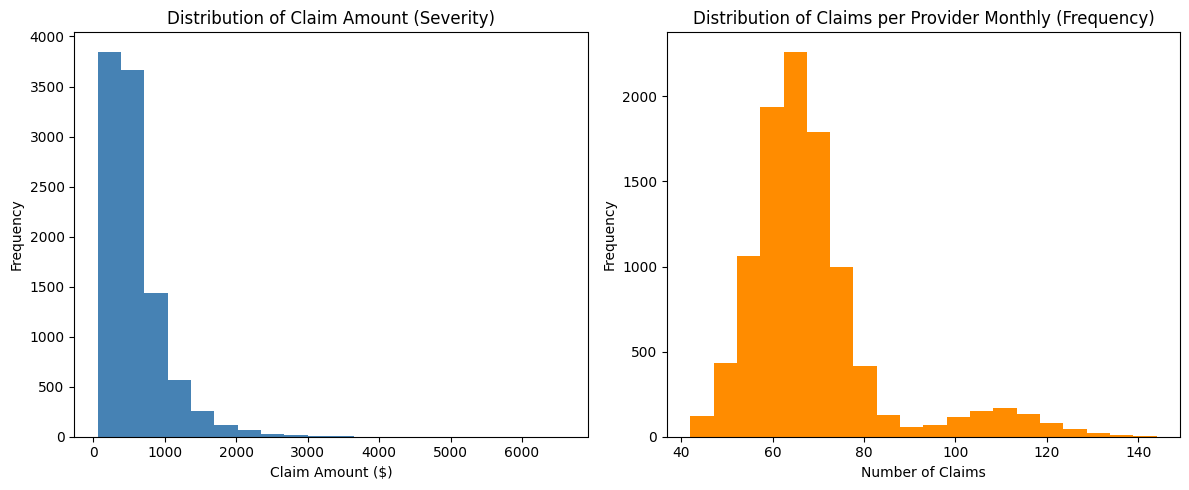

In [263]:
# Frequency vs. Severity, defined separately
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(health_data['Claim_Amount'], bins=20, color='steelblue')
axes[0].set_title('Distribution of Claim Amount (Severity)')
axes[0].set_xlabel('Claim Amount ($)')
axes[0].set_ylabel('Frequency')

axes[1].hist(health_data['No_of_Claims_Provider'], bins=20, color='darkorange')
axes[1].set_title('Distribution of Claims per Provider Monthly (Frequency)')
axes[1].set_xlabel('Number of Claims')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('frequency_severity_histograms.png', dpi=300, bbox_inches='tight')
plt.show()

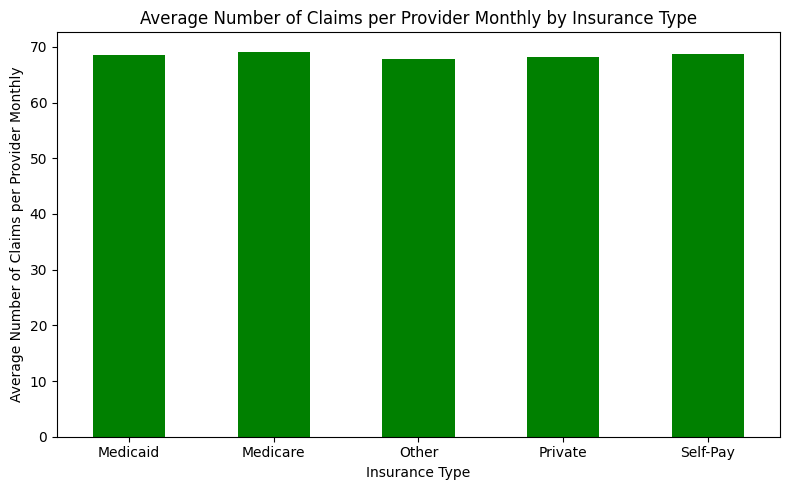

In [264]:
# What drives claim frequency
avg_claims_by_type = health_data.groupby('Insurance_Type')['No_of_Claims_Provider'].mean()

plt.figure(figsize=(8, 5))
avg_claims_by_type.plot(kind='bar', color='green')
plt.title('Average Number of Claims per Provider Monthly by Insurance Type')
plt.xlabel('Insurance Type')
plt.ylabel('Average Number of Claims per Provider Monthly')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('claims_by_insurance_type.png', dpi=300, bbox_inches='tight')
plt.show()

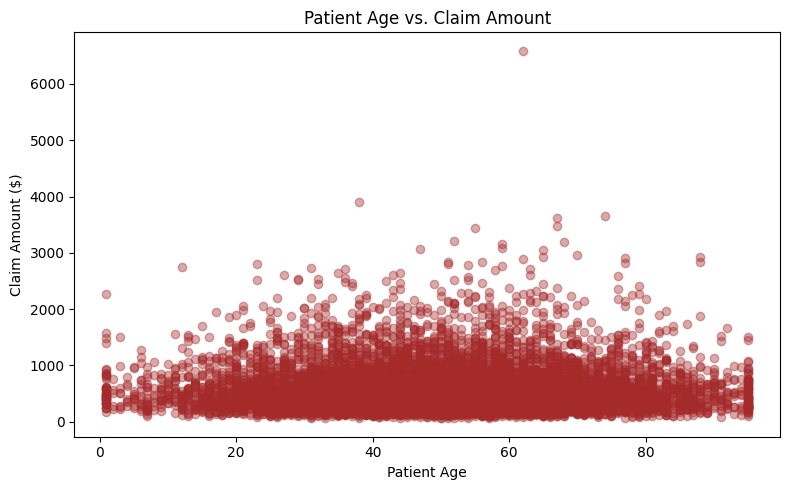

In [265]:
# What drives claim severity

plt.figure(figsize=(8, 5))
plt.scatter(health_data['Patient_Age'], health_data['Claim_Amount'], alpha=0.4, color='brown')
plt.title('Patient Age vs. Claim Amount')
plt.xlabel('Patient Age')
plt.ylabel('Claim Amount ($)')
plt.tight_layout()
plt.savefig('age_vs_claim_amount.png', dpi=300, bbox_inches='tight')
plt.show()

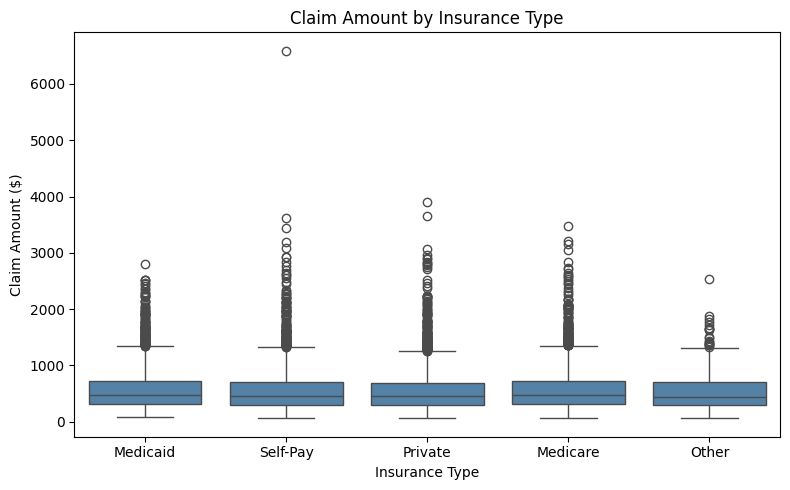

In [266]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=health_data, x='Insurance_Type', y='Claim_Amount', color='steelblue')
plt.title('Claim Amount by Insurance Type')
plt.xlabel('Insurance Type')
plt.ylabel('Claim Amount ($)')
plt.tight_layout()
plt.savefig('claim_amount_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

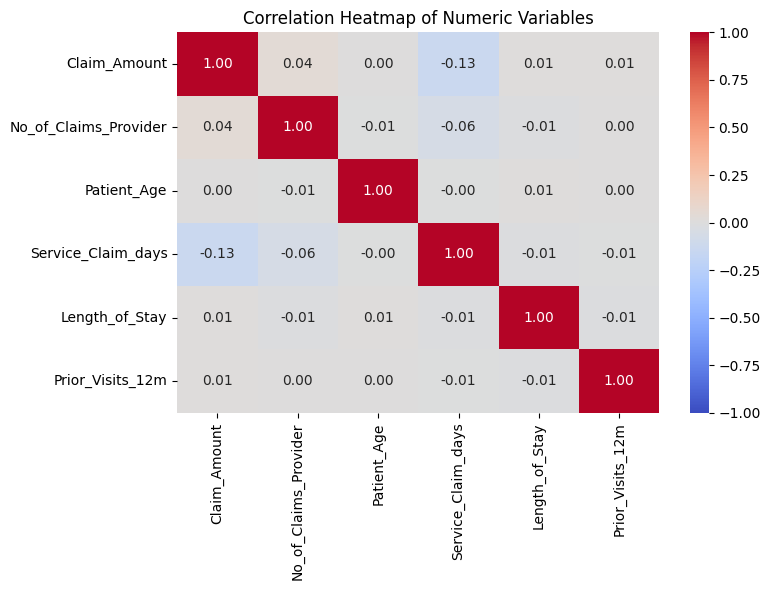

In [267]:
# Do frequency and severity share the same drivers, or differ?
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ['Claim_Amount', 'No_of_Claims_Provider', 'Patient_Age',
                 'Service_Claim_days', 'Length_of_Stay', 'Prior_Visits_12m']

corr_matrix = health_data[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

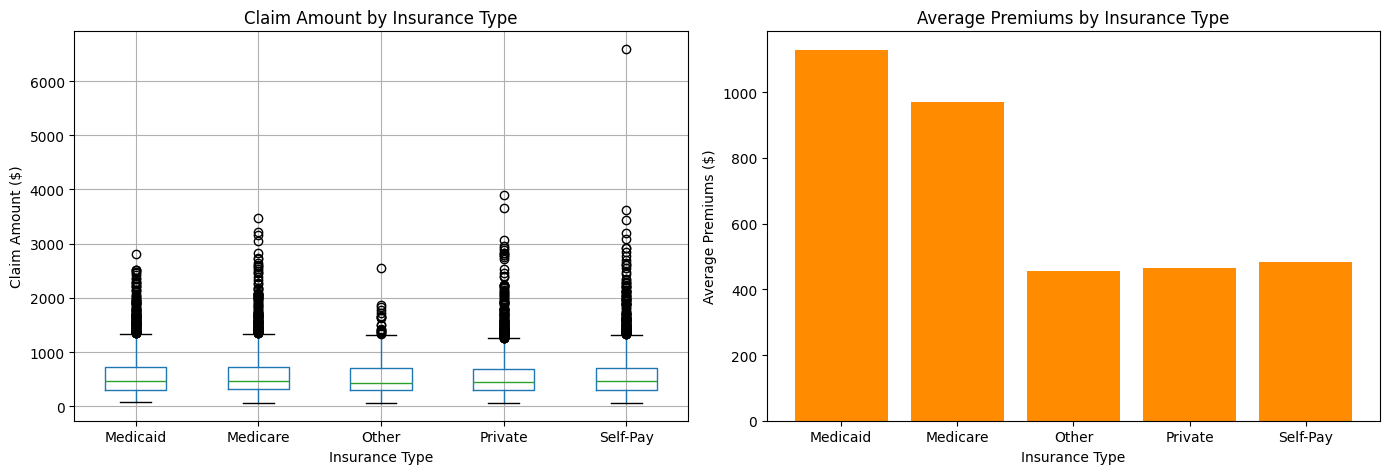

In [268]:
# Frequency and severity across coverage types
health_data['Premiums'] = pd.to_numeric(health_data['Premiums'], errors='coerce')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: boxplot of Claim_Amount by Insurance_Type
health_data.boxplot(column='Claim_Amount', by='Insurance_Type', ax=axes[0])
axes[0].set_title('Claim Amount by Insurance Type')
axes[0].set_xlabel('Insurance Type')
axes[0].set_ylabel('Claim Amount ($)')

# Right panel: bar chart of average Premiums by Insurance_Type
avg_premiums = health_data.groupby('Insurance_Type')['Premiums'].mean()
axes[1].bar(avg_premiums.index, avg_premiums.values, color='darkorange')
axes[1].set_title('Average Premiums by Insurance Type')
axes[1].set_xlabel('Insurance Type')
axes[1].set_ylabel('Average Premiums ($)')

plt.suptitle('')  # removes pandas' automatic default title
plt.tight_layout()
plt.savefig('claimamount_premiums_by_type.png', dpi=300, bbox_inches='tight')
plt.show()

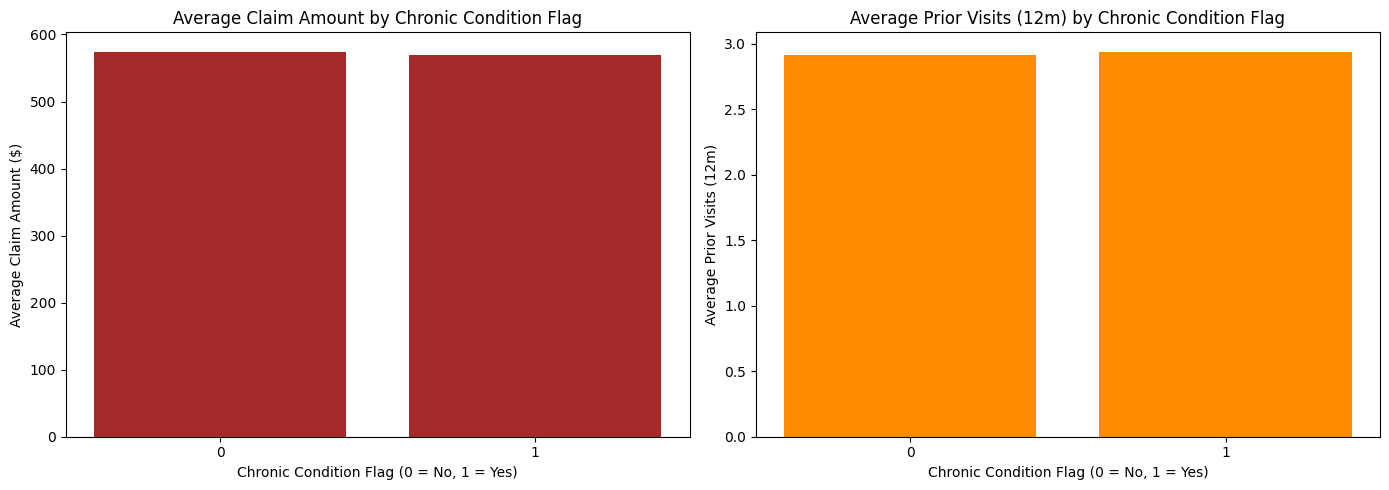

In [269]:
# Chronic conditions and behavior

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

avg_claim_chronic = health_data.groupby('Chronic_Condition_Flag')['Claim_Amount'].mean()
axes[0].bar(avg_claim_chronic.index.astype(str), avg_claim_chronic.values, color='brown')
axes[0].set_title('Average Claim Amount by Chronic Condition Flag')
axes[0].set_xlabel('Chronic Condition Flag (0 = No, 1 = Yes)')
axes[0].set_ylabel('Average Claim Amount ($)')

avg_visits_chronic = health_data.groupby('Chronic_Condition_Flag')['Prior_Visits_12m'].mean()
axes[1].bar(avg_visits_chronic.index.astype(str), avg_visits_chronic.values, color='darkorange')
axes[1].set_title('Average Prior Visits (12m) by Chronic Condition Flag')
axes[1].set_xlabel('Chronic Condition Flag (0 = No, 1 = Yes)')
axes[1].set_ylabel('Average Prior Visits (12m)')

plt.tight_layout()
plt.savefig('chronic_condition_behavior.png', dpi=300, bbox_inches='tight')
plt.show()

In [270]:
# geography effect

avg_claim_state_df = health_data.groupby('State')['Claim_Amount'].mean().reset_index()

fig = px.choropleth(
    avg_claim_state_df,
    locations='State',
    locationmode='USA-states',
    color='Claim_Amount',
    scope='usa',
    color_continuous_scale='Blues',
    title='Average Claim Amount by State'
)

# Add state abbreviation labels on top of the map
fig.add_trace(go.Scattergeo(
    locations=avg_claim_state_df['State'],
    locationmode='USA-states',
    text=avg_claim_state_df['State'],
    mode='text',
    textfont=dict(size=10, color='black')
))

fig.show()

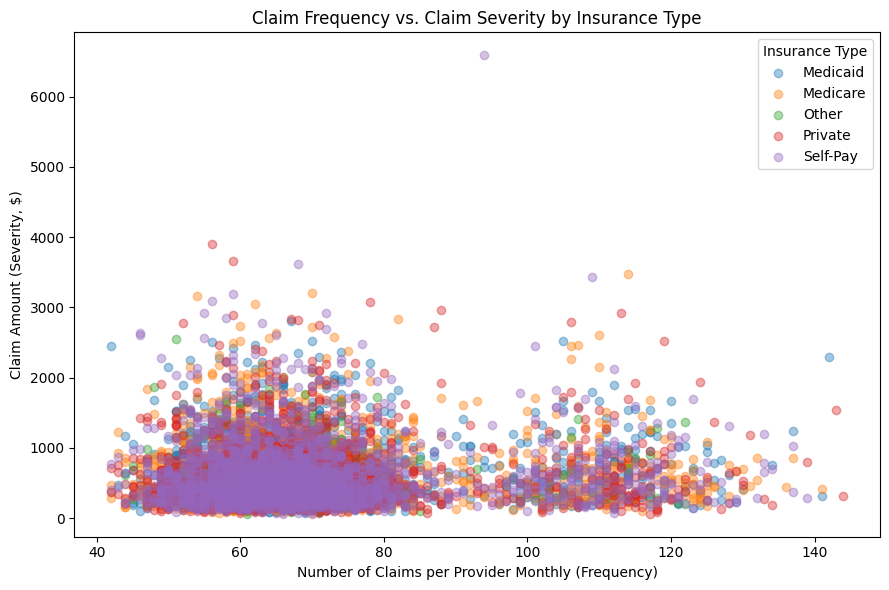

In [271]:
# Why study both together
plt.figure(figsize=(9, 6))

for ins_type, group in health_data.groupby('Insurance_Type'):
    plt.scatter(group['No_of_Claims_Provider'], group['Claim_Amount'], alpha=0.4, label=ins_type)

plt.title('Claim Frequency vs. Claim Severity by Insurance Type')
plt.xlabel('Number of Claims per Provider Monthly (Frequency)')
plt.ylabel('Claim Amount (Severity, $)')
plt.legend(title='Insurance Type')
plt.tight_layout()
plt.savefig('frequency_vs_severity_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

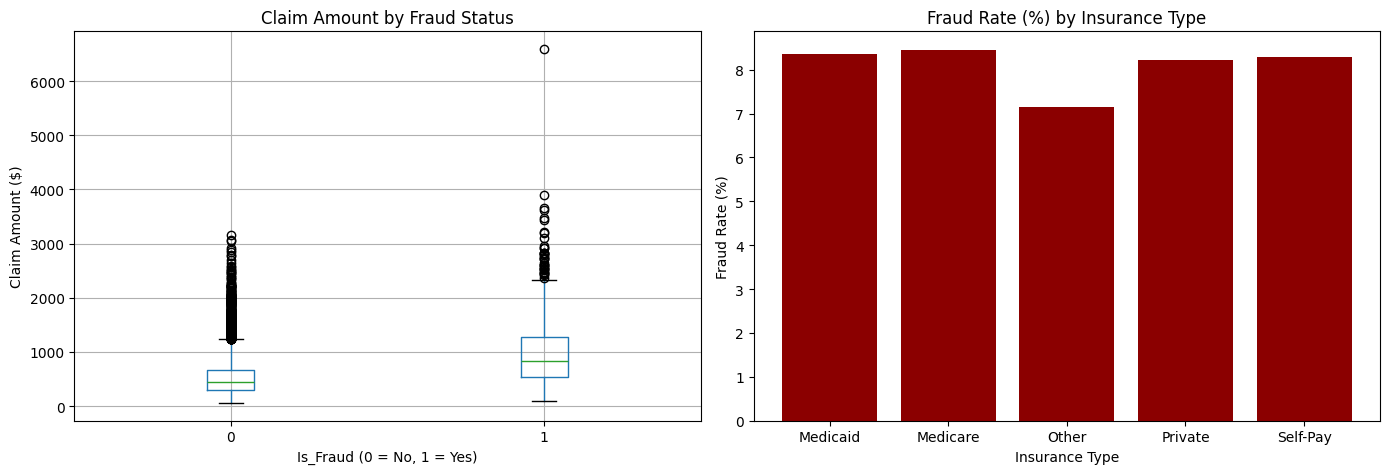

In [272]:
# Fraud Connection
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

health_data.boxplot(column='Claim_Amount', by='Is_Fraud', ax=axes[0])
axes[0].set_title('Claim Amount by Fraud Status')
axes[0].set_xlabel('Is_Fraud (0 = No, 1 = Yes)')
axes[0].set_ylabel('Claim Amount ($)')

fraud_rate_by_type = health_data.groupby('Insurance_Type')['Is_Fraud'].mean() * 100
axes[1].bar(fraud_rate_by_type.index, fraud_rate_by_type.values, color='darkred')
axes[1].set_title('Fraud Rate (%) by Insurance Type')
axes[1].set_xlabel('Insurance Type')
axes[1].set_ylabel('Fraud Rate (%)')

plt.suptitle('')
plt.tight_layout()
plt.savefig('fraud_connection.png', dpi=300, bbox_inches='tight')
plt.show()

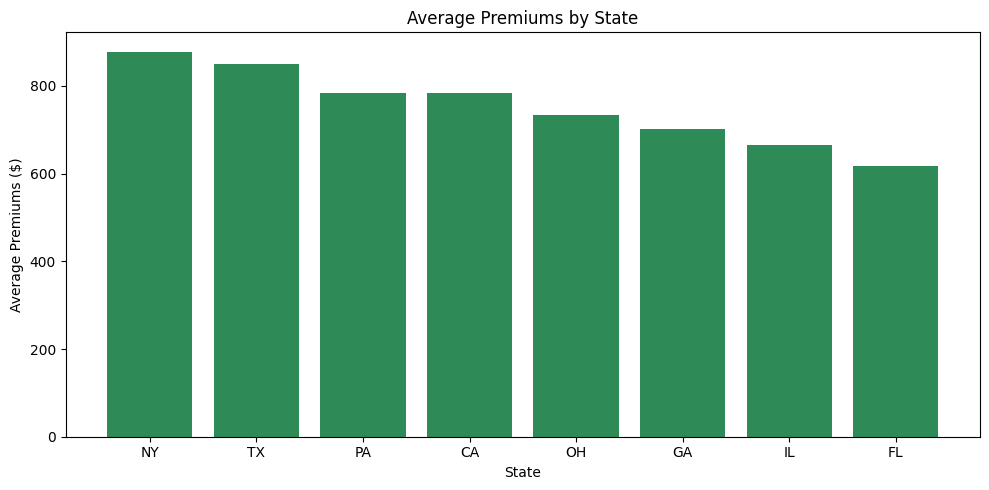

In [273]:
#Pricing Implications

avg_premium_state = health_data.groupby('State')['Premiums'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(avg_premium_state.index, avg_premium_state.values, color='seagreen')
plt.title('Average Premiums by State')
plt.xlabel('State')
plt.ylabel('Average Premiums ($)')
plt.tight_layout()
plt.savefig('premiums_by_state.png', dpi=300, bbox_inches='tight')
plt.show()

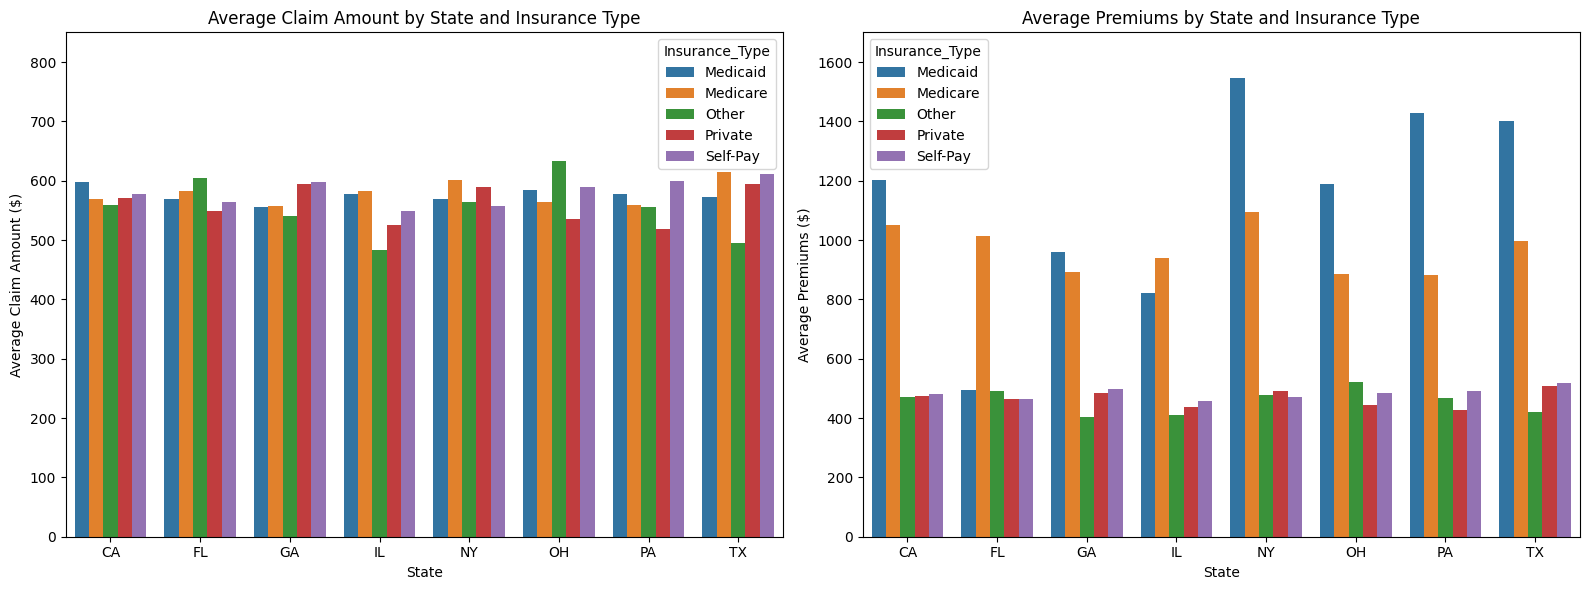

In [274]:
# Premiums vs. Claim Amount, by State and Insurance Type

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

grouped_claims = health_data.groupby(['State', 'Insurance_Type'])['Claim_Amount'].mean().reset_index()
sns.barplot(data=grouped_claims, x='State', y='Claim_Amount', hue='Insurance_Type', ax=axes[0])
axes[0].set_title('Average Claim Amount by State and Insurance Type')
axes[0].set_xlabel('State')
axes[0].set_ylabel('Average Claim Amount ($)')
axes[0].set_ylim(0, 850)
 

grouped_premiums = health_data.groupby(['State', 'Insurance_Type'])['Premiums'].mean().reset_index()
sns.barplot(data=grouped_premiums, x='State', y='Premiums', hue='Insurance_Type', ax=axes[1])
axes[1].set_title('Average Premiums by State and Insurance Type')
axes[1].set_xlabel('State')
axes[1].set_ylabel('Average Premiums ($)')
axes[1].set_ylim(0, 1700) 

plt.tight_layout()
plt.savefig('premiums_vs_claims_by_state_and_type.png', dpi=300, bbox_inches='tight')
plt.show()